# Taxis amarillos de Nueva York — datos, pronóstico y segmentación

| Artefacto | Función |
|---|---|
| `api/modelo_pronostico.ubj` | Modelo de cuantiles entrenado (XGBoost) |
| `api/demanda.parquet` | Horas del 25 de enero al 1 de febrero **con sus variables ya calculadas** |
| `api/zonas.json` | Zonas pronosticables, fechas y cuantiles para `GET /info` |
| `api/metadatos.json` | Orden de variables y categorías de zona (para cargar el modelo igual que se entrenó) |
| `app/data/zonas_segmentadas.csv` | Segmentación de zonas precalculada (K-Means + PCA) |
| `app/data/metricas.json` | Todas las cifras de la ficha del modelo |
| `app/data/monitoreo.csv` | Error día a día de la semana de prueba |

**Reglas del enunciado que se respetan en todo el notebook**

1. Viajes válidos: hora de inicio dentro de enero de 2024. Zona = `PULocationID`.
2. Zonas pronosticadas: ≥ 3,000 viajes en el mes (sin zonas "Unknown").
3. Zonas segmentadas: ≥ 500 viajes en el mes (sin zonas "Unknown").
4. Entrenamiento: hasta el 24 de enero inclusive. Prueba: 25 al 31 de enero. El 1 de febrero es «mañana» y no tiene datos reales.
5. Ningún lag menor a 24 horas: el pronóstico se hace el día anterior para todo el día siguiente.


In [1]:
# Librerías y rutas
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

# El notebook vive en `taxis-nyc/` y los datos en `Libro semana 10/`.
# Se busca la carpeta que contiene el parquet, subiendo desde el directorio actual,
def buscar_carpeta_datos() -> Path:
    candidatas = [Path.cwd(), Path.cwd() / "Libro semana 10"]
    for base in Path.cwd().parents[:3]:
        candidatas += [base, base / "Libro semana 10"]
    for carpeta in candidatas:
        if (carpeta / "yellow_tripdata_2024-01.parquet").exists():
            return carpeta
    raise FileNotFoundError(
        "No se encontró 'yellow_tripdata_2024-01.parquet'. Ejecute el notebook desde "
        "la carpeta 'Libro semana 10' o desde 'taxis-nyc'."
    )


BASE = buscar_carpeta_datos()
PROYECTO = BASE / "taxis-nyc"
DIR_API = PROYECTO / "api"
DIR_APP = PROYECTO / "app"
DIR_DATOS_APP = DIR_APP / "data"
for carpeta in (DIR_API, DIR_DATOS_APP, DIR_APP / "paginas", DIR_APP / ".streamlit"):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Carpeta de datos :", BASE)
print("Carpeta proyecto :", PROYECTO)


Carpeta de datos : f:\Documentos\Tareas\AIMLT\Libro_semana_10
Carpeta proyecto : f:\Documentos\Tareas\AIMLT\Libro_semana_10\taxis-nyc


## 1 · Carga de datos y filtros

Se leen solo las columnas que se necesitan del parquet local (3 millones de filas, ~50 MB).
`trip_distance` y `fare_amount` se usan después para la segmentación; el resto del pronóstico
solo necesita la hora de inicio y la zona de origen.


In [2]:
FECHA_INICIO = pd.Timestamp("2024-01-01")
FECHA_FIN = pd.Timestamp("2024-02-01")        # límite exclusivo: enero completo
FECHA_MANANA = pd.Timestamp("2024-02-01")     # el "mañana" que se pronostica
FECHA_CORTE = pd.Timestamp("2024-01-24 23:00")  # último instante de entrenamiento

COLUMNAS = ["tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount"]
viajes = pd.read_parquet(BASE / "yellow_tripdata_2024-01.parquet", columns=COLUMNAS)
zonas_tabla = pd.read_csv(BASE / "taxi_zone_lookup.csv")

# Regla 1: solo viajes que inician en enero de 2024
viajes = viajes[(viajes["tpep_pickup_datetime"] >= FECHA_INICIO) & (viajes["tpep_pickup_datetime"] < FECHA_FIN)]

# Regla: fuera las zonas "Unknown"
zonas_unknown = set(
    zonas_tabla.loc[
        zonas_tabla["Zone"].str.contains("Unknown", case=False, na=False)
        | zonas_tabla["Zone"].isna()
        | zonas_tabla["Borough"].str.contains("Unknown", case=False, na=False),
        "LocationID",
    ]
)
viajes = viajes[~viajes["PULocationID"].isin(zonas_unknown)].copy()

print(f"Viajes válidos en enero de 2024 : {len(viajes):,}")
print(f"Zonas 'Unknown' descartadas     : {sorted(zonas_unknown)}")
print(f"Zonas de origen distintas       : {viajes['PULocationID'].nunique()}")


Viajes válidos en enero de 2024 : 2,954,246
Zonas 'Unknown' descartadas     : [264]
Zonas de origen distintas       : 259


### 1.1 · Zonas que se pronostican y zonas que se segmentan

El umbral de 3,000 viajes deja fuera las zonas con muy poco movimiento: un modelo horario sobre
20 viajes al mes no aprende nada y solo produce ruido. El umbral de 500 se usa para la segmentación,
donde sí interesa describir también zonas tranquilas.


In [3]:
conteo_zonas = viajes["PULocationID"].value_counts()

ZONAS_PRONOSTICO = sorted(conteo_zonas[conteo_zonas >= 3000].index.tolist())
ZONAS_SEGMENTO = sorted(conteo_zonas[conteo_zonas >= 500].index.tolist())

print(f"Zonas pronosticadas (≥ 3,000 viajes): {len(ZONAS_PRONOSTICO)}")
print(f"Zonas segmentadas   (≥   500 viajes): {len(ZONAS_SEGMENTO)}")
print(f"Viajes cubiertos por el pronóstico  : {conteo_zonas.loc[ZONAS_PRONOSTICO].sum():,} "
      f"({conteo_zonas.loc[ZONAS_PRONOSTICO].sum() / len(viajes):.1%})")


Zonas pronosticadas (≥ 3,000 viajes): 58
Zonas segmentadas   (≥   500 viajes): 101
Viajes cubiertos por el pronóstico  : 2,885,953 (97.7%)


## 2 · De viajes a una serie de tiempo horaria (los 5 pasos del enunciado)

1. Redondear la hora de inicio con `.dt.floor("h")`.
2. Contar viajes por zona y hora.
3. Rellenar con 0 las horas sin viajes (con `pd.MultiIndex.from_product` y `reindex`).
4. Agregar las 24 horas del 1 de febrero, vacías: son las que se van a pronosticar.
5. Crear las variables con `groupby("PULocationID").shift(...)` para que los valores de una zona
   nunca se mezclen con los de otra.


In [4]:
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")

serie = viajes.groupby(["PULocationID", "hora"], observed=True).size().rename("viajes")

# Todas las combinaciones zona × hora, del 1 de enero a las 23:00 del 1 de febrero
horas = pd.date_range("2024-01-01", "2024-02-01 23:00", freq="h")
indice = pd.MultiIndex.from_product([ZONAS_PRONOSTICO, horas], names=["PULocationID", "hora"])

demanda = (
    serie.reindex(indice, fill_value=0)
    .rename_axis(["PULocationID", "hora"])
    .reset_index()
    .sort_values(["PULocationID", "hora"])
    .reset_index(drop=True)
)

demanda["viajes"] = demanda["viajes"].astype("int64")
print(f"Filas zona-hora (59 zonas × 768 horas): {len(demanda):,}")
print(f"Ceros rellenados                      : {int((demanda['viajes'] == 0).sum()):,}")
print(demanda.head())


Filas zona-hora (59 zonas × 768 horas): 44,544
Ceros rellenados                      : 3,185
   PULocationID                hora  viajes
0             4 2024-01-01 00:00:00      25
1             4 2024-01-01 01:00:00      29
2             4 2024-01-01 02:00:00      34
3             4 2024-01-01 03:00:00      31
4             4 2024-01-01 04:00:00      32


### 2.1 · Variables del modelo

| Variable | Qué es |
|---|---|
| `lag_24`, `lag_48` | viajes a la misma hora de ayer y de anteayer |
| `lag_167`, `lag_168`, `lag_169` | misma hora de hace una semana, y una hora antes y después |
| `media_dia_ant` | promedio de viajes por hora del día anterior completo |
| `hora_dia`, `dia_semana`, `feriado` | calendario (el 15 de enero de 2024 fue feriado) |
| `PULocationID` | zona, como categoría nativa de XGBoost |

**Ningún lag menor a 24 h.** Si se usara `lag_1`, el modelo vería en el notebook los viajes de la
hora anterior y parecería excelente, pero en producción se pronostica el día entero con un día de
antelación: esa información no existe. Sería fuga de datos.


In [5]:
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek          # 0 = lunes
FERIADOS = {pd.Timestamp("2024-01-01").date(), pd.Timestamp("2024-01-15").date()}  # Año Nuevo y MLK
demanda["feriado"] = demanda["hora"].dt.date.isin(FERIADOS).astype("int8")

por_zona = demanda.groupby("PULocationID", observed=True)["viajes"]
demanda["lag_24"] = por_zona.shift(24)
demanda["lag_48"] = por_zona.shift(48)
demanda["lag_167"] = por_zona.shift(167)
demanda["lag_168"] = por_zona.shift(168)
demanda["lag_169"] = por_zona.shift(169)
demanda["media_dia_ant"] = por_zona.transform(lambda s: s.shift(24).rolling(24).mean())

VARIABLES = [
    "lag_24", "lag_48", "lag_167", "lag_168", "lag_169",
    "media_dia_ant", "hora_dia", "dia_semana", "feriado", "PULocationID",
]
CATEGORIAS = sorted(pd.unique(demanda["PULocationID"]).tolist())

print(demanda[["PULocationID", "hora", "viajes"] + VARIABLES[:6]].head(10).to_string())
print("\nFilas con alguna variable faltante:", int(demanda[VARIABLES].isna().any(axis=1).sum()))


   PULocationID                hora  viajes  lag_24  lag_48  lag_167  lag_168  lag_169  media_dia_ant
0             4 2024-01-01 00:00:00      25     NaN     NaN      NaN      NaN      NaN            NaN
1             4 2024-01-01 01:00:00      29     NaN     NaN      NaN      NaN      NaN            NaN
2             4 2024-01-01 02:00:00      34     NaN     NaN      NaN      NaN      NaN            NaN
3             4 2024-01-01 03:00:00      31     NaN     NaN      NaN      NaN      NaN            NaN
4             4 2024-01-01 04:00:00      32     NaN     NaN      NaN      NaN      NaN            NaN
5             4 2024-01-01 05:00:00       8     NaN     NaN      NaN      NaN      NaN            NaN
6             4 2024-01-01 06:00:00       6     NaN     NaN      NaN      NaN      NaN            NaN
7             4 2024-01-01 07:00:00       4     NaN     NaN      NaN      NaN      NaN            NaN
8             4 2024-01-01 08:00:00       0     NaN     NaN      NaN      NaN     

## 3 · División por tiempo (nunca `train_test_split`)

El negocio consiste en pronosticar **hacia adelante**. Mezclar días al azar haría que el modelo
viera el futuro y las métricas no significarían nada.


In [6]:
def preparar_matriz(df: pd.DataFrame) -> pd.DataFrame:
    """Devuelve las variables en el orden exacto y con la zona como categoría nativa."""
    matriz = df[VARIABLES].copy()
    matriz["PULocationID"] = pd.Categorical(matriz["PULocationID"], categories=CATEGORIAS)
    return matriz


entrenamiento = demanda[(demanda["hora"] <= FECHA_CORTE) & demanda[VARIABLES].notna().all(axis=1)].copy()
prueba = demanda[(demanda["hora"] > FECHA_CORTE) & (demanda["hora"] < FECHA_MANANA)].copy()
manana = demanda[demanda["hora"] >= FECHA_MANANA].copy()

print(f"Entrenamiento: {entrenamiento['hora'].min():%Y-%m-%d %H:%M} → {entrenamiento['hora'].max():%Y-%m-%d %H:%M} "
      f"({len(entrenamiento):,} filas)")
print(f"Prueba       : {prueba['hora'].min():%Y-%m-%d %H:%M} → {prueba['hora'].max():%Y-%m-%d %H:%M} "
      f"({len(prueba):,} filas)")
print(f"Mañana       : {manana['hora'].min():%Y-%m-%d %H:%M} → {manana['hora'].max():%Y-%m-%d %H:%M} "
      f"({len(manana):,} filas, sin datos reales)")


Entrenamiento: 2024-01-08 01:00 → 2024-01-24 23:00 (23,606 filas)
Prueba       : 2024-01-25 00:00 → 2024-01-31 23:00 (9,744 filas)
Mañana       : 2024-02-01 00:00 → 2024-02-01 23:00 (1,392 filas, sin datos reales)


## 4 · Modelo de cuantiles

Se usa un solo `XGBRegressor` con `objective="reg:quantileerror"` y nueve cuantiles
(p10, p20, …, p90): el mismo modelo entrega todos los cuantiles de una vez y con
`multi_strategy="multi_output_tree"` crece poco. Los cuantiles se entregan en crudo y pueden
cruzarse (un p60 menor que el p50), así que **cada fila se ordena con `np.sort(..., axis=1)`**.


In [7]:
CUANTILES = [float(round(q, 2)) for q in np.arange(0.1, 1.0, 0.1)]
NOMBRES_CUANTILES = [f"p{int(round(q * 100))}" for q in CUANTILES]
print("Cuantiles del modelo:", NOMBRES_CUANTILES)

modelo = xgb.XGBRegressor(
    objective="reg:quantileerror",
    quantile_alpha=CUANTILES,
    n_estimators=250,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=5,
    tree_method="hist",
    multi_strategy="multi_output_tree",
    enable_categorical=True,
    random_state=42,
    n_jobs=-1,
)

modelo.fit(preparar_matriz(entrenamiento), entrenamiento["viajes"].to_numpy())

pred_prueba = np.sort(modelo.predict(preparar_matriz(prueba)), axis=1)
pred_manana = np.sort(modelo.predict(preparar_matriz(manana)), axis=1)

print("Forma de la predicción (filas, cuantiles):", pred_prueba.shape)
print("¿Cuántas filas tenían los cuantiles cruzados antes de ordenar?",
      int((np.diff(modelo.predict(preparar_matriz(prueba)), axis=1) < 0).any(axis=1).sum()))


Cuantiles del modelo: ['p10', 'p20', 'p30', 'p40', 'p50', 'p60', 'p70', 'p80', 'p90']


Forma de la predicción (filas, cuantiles): (9744, 9)
¿Cuántas filas tenían los cuantiles cruzados antes de ordenar? 0


## 5 · Evaluación por tiempo y comparación con la regla simple

La regla simple es **«igual que hace una semana»**: usar `lag_168` como pronóstico.
Se comparan tres cosas:

* **MAE de la mediana** (p50) contra el MAE de la regla simple,
* **pérdida pinball**, que es la métrica propia de los cuantiles (penaliza de forma asimétrica),
* **cobertura del rango del 80 %**: qué porcentaje de valores reales cae entre p10 y p90.
  Si el rango está bien calibrado, debería rondar el 80 %.


In [8]:
def perdida_pinball(real: np.ndarray, pred: np.ndarray, cuantiles: list[float]) -> float:
    errores = real[:, None] - pred
    return float(np.mean(np.maximum(cuantiles * errores, (np.array(cuantiles) - 1) * errores)))


def cobertura(real: np.ndarray, inferior: np.ndarray, superior: np.ndarray) -> float:
    return float(np.mean((real >= inferior) & (real <= superior)))


real_prueba = prueba["viajes"].to_numpy()
mediana = pred_prueba[:, NOMBRES_CUANTILES.index("p50")]
base_prueba = prueba["lag_168"].to_numpy()

mae_modelo = float(np.mean(np.abs(real_prueba - mediana)))
mae_base = float(np.mean(np.abs(real_prueba - base_prueba)))
pinball = perdida_pinball(real_prueba, pred_prueba, CUANTILES)
cob_80 = cobertura(real_prueba, pred_prueba[:, 0], pred_prueba[:, 8])

print(f"MAE mediana del modelo      : {mae_modelo:7.2f} viajes/hora")
print(f"MAE regla 'hace una semana' : {mae_base:7.2f} viajes/hora")
print(f"Mejora relativa             : {(1 - mae_modelo / mae_base):+.1%}")
print(f"Pérdida pinball (9 cuantiles): {pinball:7.2f}")
print(f"Cobertura del rango 80 %    : {cob_80:7.1%}")


MAE mediana del modelo      :   11.71 viajes/hora
MAE regla 'hace una semana' :   11.88 viajes/hora
Mejora relativa             : +1.5%
Pérdida pinball (9 cuantiles):    4.58
Cobertura del rango 80 %    :   86.7%


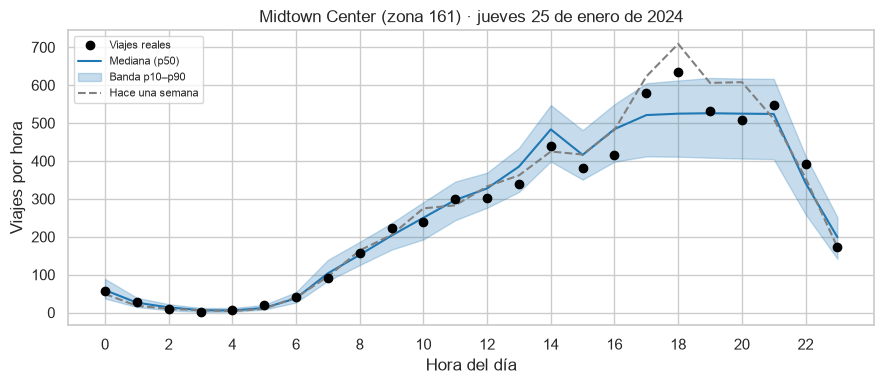

In [9]:
# Vista de un día de la semana de prueba: mediana, banda p10–p90, real y regla simple
ZONA_EJEMPLO = 161  # Midtown Center
filtro_dia = (prueba["PULocationID"] == ZONA_EJEMPLO) & (prueba["hora"].dt.normalize() == pd.Timestamp("2024-01-25"))
dia = prueba.loc[filtro_dia]
pos = np.flatnonzero(filtro_dia.to_numpy())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(dia["hora_dia"], real_prueba[pos], "o", color="black", label="Viajes reales", zorder=5)
ax.plot(dia["hora_dia"], mediana[pos], color="#1f77b4", label="Mediana (p50)")
ax.fill_between(dia["hora_dia"], pred_prueba[pos, 0], pred_prueba[pos, 8], alpha=0.25,
                color="#1f77b4", label="Banda p10–p90")
ax.plot(dia["hora_dia"], dia["lag_168"], linestyle="--", color="gray", label="Hace una semana")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Viajes por hora")
ax.set_title(f"Midtown Center (zona {ZONA_EJEMPLO}) · jueves 25 de enero de 2024")
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [10]:
# Cobertura y error por cuantil: sirve para comprobar que la banda no esconde el problema
filas_cuantiles = []
for posicion, nombre in enumerate(NOMBRES_CUANTILES):
    filas_cuantiles.append(
        {
            "cuantil": nombre,
            "cobertura_por_debajo": float(np.mean(real_prueba <= pred_prueba[:, posicion])),
            "error_absoluto_medio": float(np.mean(np.abs(real_prueba - pred_prueba[:, posicion]))),
        }
    )
tabla_cuantiles = pd.DataFrame(filas_cuantiles)
print(tabla_cuantiles.to_string(index=False))


cuantil  cobertura_por_debajo  error_absoluto_medio
    p10              0.071531             19.916640
    p20              0.184626             14.950929
    p30              0.298748             12.843085
    p40              0.414614             11.844891
    p50              0.527196             11.706936
    p60              0.631876             12.340764
    p70              0.732451             14.007398
    p80              0.831794             17.066712
    p90              0.938732             23.863424


### 5.1 · Comparación de costos

Conviene enviar **más** que la mediana. El cuantil óptimo es

$$\text{cuantil}^* = \frac{C_{\text{pasajero perdido}}}{C_{\text{pasajero perdido}} + C_{\text{taxi ocioso}}}$$

y la cantidad recomendada es la de ese cuantil del pronóstico.


In [11]:
COSTO_OCIOSO, COSTO_PERDIDO = 10.0, 40.0


def cuantil_optimo(costo_ocioso: float, costo_perdido: float) -> float:
    return costo_perdido / (costo_perdido + costo_ocioso)


def costo_horario(enviados, real, costo_ocioso=COSTO_OCIOSO, costo_perdido=COSTO_PERDIDO):
    enviados = np.asarray(enviados, dtype=float)
    real = np.asarray(real, dtype=float)
    return np.maximum(enviados - real, 0) * costo_ocioso + np.maximum(real - enviados, 0) * costo_perdido


q_opt = cuantil_optimo(COSTO_OCIOSO, COSTO_PERDIDO)
indice_opt = int(np.argmin(np.abs(np.array(CUANTILES) - q_opt)))
print(f"Cuantil óptimo con ${COSTO_PERDIDO:.0f} de pasajero perdido y ${COSTO_OCIOSO:.0f} de taxi ocioso: {q_opt:.2f}")
print(f"Se usa el cuantil más cercano del modelo: {NOMBRES_CUANTILES[indice_opt]}")

rec_prueba = pred_prueba[:, indice_opt]
costo_recomendacion = costo_horario(rec_prueba, real_prueba).sum()
costo_mediana = costo_horario(mediana, real_prueba).sum()
costo_base = costo_horario(base_prueba, real_prueba).sum()

print(f"\nCosto de la semana de prueba (todas las zonas)")
print(f"  recomendación ({NOMBRES_CUANTILES[indice_opt]}) : ${costo_recomendacion:,.0f}")
print(f"  pronóstico central (p50)          : ${costo_mediana:,.0f}")
print(f"  igual que hace una semana         : ${costo_base:,.0f}")


Cuantil óptimo con $40 de pasajero perdido y $10 de taxi ocioso: 0.80
Se usa el cuantil más cercano del modelo: p80

Costo de la semana de prueba (todas las zonas)
  recomendación (p80) : $2,257,233
  pronóstico central (p50)          : $2,944,294
  igual que hace una semana         : $3,160,950


In [12]:
# Ejemplo del enunciado: miércoles 31 de enero en Midtown Center (zona 161)
filtro_midtown = (prueba["PULocationID"] == 161) & (prueba["hora"].dt.normalize() == pd.Timestamp("2024-01-31"))
pos_midtown = np.flatnonzero(filtro_midtown.to_numpy())
ejemplo = prueba.loc[filtro_midtown]
costo_ejemplo = {
    "zona": "Midtown Center",
    "fecha": "2024-01-31",
    "cuantil": NOMBRES_CUANTILES[indice_opt],
    "recomendacion": float(costo_horario(rec_prueba[pos_midtown], ejemplo["viajes"]).sum()),
    "p50": float(costo_horario(mediana[pos_midtown], ejemplo["viajes"]).sum()),
    "hace_una_semana": float(costo_horario(base_prueba[pos_midtown], ejemplo["viajes"]).sum()),
}
print(json.dumps(costo_ejemplo, indent=2, ensure_ascii=False))


{
  "zona": "Midtown Center",
  "fecha": "2024-01-31",
  "cuantil": "p80",
  "recomendacion": 9373.95453453064,
  "p50": 14140.06175994873,
  "hace_una_semana": 15880.0
}


## 6 · Segmentación de zonas (K-Means + PCA)

Se describe **cómo se usa cada zona**, no cuánto se gana en ella. Todas las variables se escalan
con `StandardScaler` porque K-Means mide distancias euclidianas y una variable en viajes/día
(decenas a miles) aplastaría a las demás (porcentajes de 0 a 100).

Para distancia y tarifa se descartan antes los viajes con valor cero o negativo.


In [13]:
seg = viajes[viajes["PULocationID"].isin(ZONAS_SEGMENTO)].copy()
validos = seg[(seg["trip_distance"] > 0) & (seg["fare_amount"] > 0)]

totales = seg.groupby("PULocationID", observed=True).size().rename("viajes_mes")
medias = validos.groupby("PULocationID", observed=True).agg(
    distancia_mediana=("trip_distance", "median"),
    tarifa_mediana=("fare_amount", "median"),
    propina_mediana=("tip_amount", "median"),
)

hora_dia = seg["tpep_pickup_datetime"].dt.hour
seg["hora_dia"] = hora_dia
seg["es_fin_semana"] = seg["tpep_pickup_datetime"].dt.dayofweek >= 5

resumen = pd.DataFrame(index=medias.index)
resumen["viajes_mes"] = totales
resumen["viajes_dia"] = totales / 31
resumen["log_viajes_dia"] = np.log1p(resumen["viajes_dia"])
resumen = resumen.join(medias)

# Porcentajes por franja horaria y de fin de semana (sobre los viajes de cada zona)
franjas = pd.DataFrame(index=resumen.index)
franjas["pct_fin_semana"] = seg.groupby("PULocationID", observed=True)["es_fin_semana"].mean() * 100
franjas["pct_6_10"] = seg.assign(f=(hora_dia >= 6) & (hora_dia <= 10)).groupby("PULocationID", observed=True)["f"].mean() * 100
franjas["pct_16_20"] = seg.assign(f=(hora_dia >= 16) & (hora_dia <= 20)).groupby("PULocationID", observed=True)["f"].mean() * 100
franjas["pct_22_5"] = seg.assign(f=(hora_dia >= 22) | (hora_dia <= 5)).groupby("PULocationID", observed=True)["f"].mean() * 100
resumen = resumen.join(franjas)

VARIABLES_SEGMENTO = [
    "log_viajes_dia", "distancia_mediana", "tarifa_mediana", "propina_mediana",
    "pct_fin_semana", "pct_6_10", "pct_16_20", "pct_22_5",
]

print(f"Zonas segmentadas: {len(resumen)}")
print(f"Viajes descartados por distancia/tarifa inválida: {len(seg) - len(validos):,}")
print(resumen[VARIABLES_SEGMENTO].describe().round(2).to_string())


Zonas segmentadas: 101
Viajes descartados por distancia/tarifa inválida: 90,471
       log_viajes_dia  distancia_mediana  tarifa_mediana  propina_mediana  pct_fin_semana  pct_6_10  pct_16_20  pct_22_5
count          101.00             101.00          101.00           101.00          101.00    101.00     101.00    101.00
mean             5.44               3.47           20.44             1.95           26.39     22.01      26.40     20.21
std              1.96               2.79           12.39             2.06            8.53     11.28       8.29     13.42
min              2.85               1.23           10.00             0.00           10.35      4.86       6.98      2.40
25%              3.44               1.61           12.10             0.00           21.49     13.60      21.06     11.68
50%              5.40               2.53           17.00             2.44           25.53     21.35      27.73     17.67
75%              7.35               4.13           24.50             2.80

In [14]:
escalador = StandardScaler()
matriz_zonas = escalador.fit_transform(resumen[VARIABLES_SEGMENTO])


### 6.1 · Justificación con el coeficiente de silueta

La silueta mide, para cada zona, qué tan parecida es a su propio grupo comparada con el grupo
vecino (−1 a 1; más alto es mejor). Se prueban k de 2 a 7.


In [15]:
resultados_silueta = {}
etiquetas = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas[k] = km.fit_predict(matriz_zonas)
    resultados_silueta[k] = float(silhouette_score(matriz_zonas, etiquetas[k]))

tabla_silueta = pd.DataFrame(
    {"k": list(resultados_silueta), "silueta": [round(v, 4) for v in resultados_silueta.values()]}
)
mejor_k = max(resultados_silueta, key=resultados_silueta.get)
print(tabla_silueta.to_string(index=False))
print(f"\nMejor k por silueta: {mejor_k} ({resultados_silueta[mejor_k]:.4f})")


 k  silueta
 2   0.3405
 3   0.3756
 4   0.4150
 5   0.3771
 6   0.3635
 7   0.3682

Mejor k por silueta: 4 (0.4150)


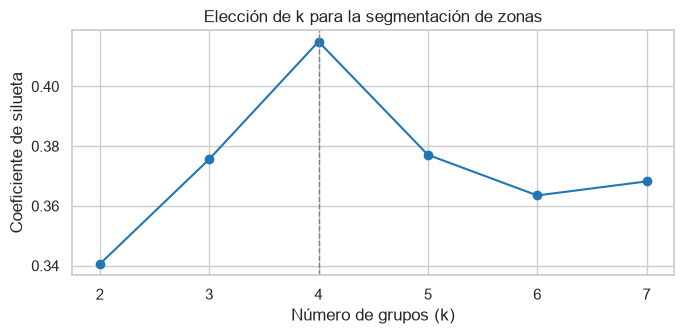

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tabla_silueta["k"], tabla_silueta["silueta"], marker="o", color="#1f77b4")
ax.axvline(mejor_k, linestyle="--", color="gray", linewidth=1)
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Coeficiente de silueta")
ax.set_title("Elección de k para la segmentación de zonas")
plt.tight_layout()
plt.show()


### 6.2 · K-Means con el k elegido y PCA a dos dimensiones

El PCA permite dibujar las 102 zonas en un plano. Se informa **cuánta variación conservan** los
dos componentes: si es poca, el dibujo es solo una vista parcial de la realidad.


In [17]:
kmeans = KMeans(n_clusters=mejor_k, n_init=10, random_state=42)
resumen["grupo_id"] = kmeans.fit_predict(matriz_zonas)

pca = PCA(n_components=2, random_state=42)
componentes = pca.fit_transform(matriz_zonas)
resumen["pc1"] = componentes[:, 0]
resumen["pc2"] = componentes[:, 1]
varianza = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1 y PC2: {varianza[0]:.1%} + {varianza[1]:.1%} = {varianza.sum():.1%}")


Varianza explicada por PC1 y PC2: 37.7% + 27.0% = 64.8%


### 6.3 · Nombre de cada grupo **según su perfil**

K-Means numera los grupos al azar: el grupo 0 de hoy puede ser el 2 mañana. Por eso los nombres se
asignan con reglas sobre el perfil de cada grupo, no con un diccionario fijo por número.


In [18]:
perfil_grupos = resumen.groupby("grupo_id")[VARIABLES_SEGMENTO + ["viajes_dia"]].mean()

REGLAS_NOMBRE = [
    ("distancia_mediana", "Aeropuertos y viajes largos", 1.30),
    ("pct_22_5", "Zonas nocturnas", None),
    ("pct_16_20", "Zonas de oficinas y tarde", None),
    ("pct_fin_semana", "Zonas de ocio de fin de semana", None),
    ("pct_6_10", "Zonas madrugadoras", None),
    ("viajes_dia", "Zonas muy transitadas", None),
    ("tarifa_mediana", "Viajes de tarifa alta", None),
    ("propina_mediana", "Viajes con buena propina", None),
]

# Un nombre solo se asigna si el grupo se aparta del promedio (z ≥ 0.5).
# Si ningún perfil destaca, el grupo que queda es simplemente el de menor volumen.
perfil_z = (perfil_grupos - perfil_grupos.mean()) / perfil_grupos.std(ddof=0)

nombres = {}
pendientes = set(perfil_grupos.index)
for variable, nombre, salto in REGLAS_NOMBRE:
    if not pendientes:
        break
    candidato = perfil_grupos.loc[list(pendientes), variable].idxmax()
    if perfil_z.loc[candidato, variable] < 0.5:
        break
    if salto is not None:
        otros = perfil_grupos.loc[[g for g in pendientes if g != candidato], variable]
        if otros.empty or perfil_grupos.loc[candidato, variable] < salto * otros.max():
            continue
    nombres[candidato] = nombre
    pendientes.discard(candidato)

for grupo in pendientes:  # el grupo que queda es el de menor volumen
    nombres[grupo] = "Zonas de barrio con poca demanda"

resumen["grupo"] = resumen["grupo_id"].map(nombres)


def describir_grupo(fila: pd.Series) -> str:
    return (
        f"{fila['viajes_dia']:.0f} viajes/día · distancia mediana {fila['distancia_mediana']:.1f} mi · "
        f"tarifa mediana ${fila['tarifa_mediana']:.0f} · {fila['pct_22_5']:.0f} % de viajes de noche · "
        f"{fila['pct_fin_semana']:.0f} % en fin de semana"
    )


descripciones = perfil_grupos.apply(describir_grupo, axis=1)
resumen["descripcion"] = resumen["grupo_id"].map(descripciones)

tamano = resumen.groupby(["grupo_id", "grupo"]).size().rename("zonas").reset_index()
print(tamano.to_string(index=False))
print()
print(perfil_grupos.round(1).to_string())


 grupo_id                            grupo  zonas
        0 Zonas de barrio con poca demanda     38
        1                  Zonas nocturnas     12
        2        Zonas de oficinas y tarde     46
        3      Aeropuertos y viajes largos      5

          log_viajes_dia  distancia_mediana  tarifa_mediana  propina_mediana  pct_fin_semana  pct_6_10  pct_16_20  pct_22_5  viajes_dia
grupo_id                                                                                                                               
0                    3.6                4.4            25.1              0.2            22.7      31.7       19.7      19.2        43.7
1                    5.5                2.6            16.7              1.8            43.7       9.3       20.6      49.5       700.2
2                    6.9                2.0            13.5              2.7            24.8      17.8       32.9      13.6      1662.2
3                    5.8               12.0            58.2          

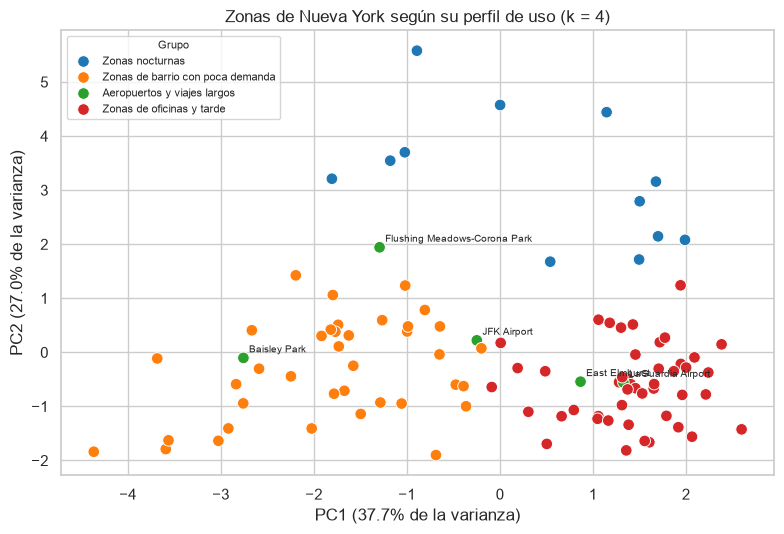

In [19]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=resumen, x="pc1", y="pc2", hue="grupo", s=70, ax=ax, palette="tab10")
nombre_zona = zonas_tabla.set_index("LocationID")["Zone"]
etiquetas_aeropuerto = resumen[resumen["grupo"] == "Aeropuertos y viajes largos"]
for zona_id, fila in etiquetas_aeropuerto.iterrows():
    ax.annotate(nombre_zona.get(zona_id, str(zona_id)), (fila["pc1"], fila["pc2"]),
                fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"PC1 ({varianza[0]:.1%} de la varianza)")
ax.set_ylabel(f"PC2 ({varianza[1]:.1%} de la varianza)")
ax.set_title(f"Zonas de Nueva York según su perfil de uso (k = {mejor_k})")
ax.legend(title="Grupo", fontsize=8, title_fontsize=8, loc="best")
plt.tight_layout()
plt.show()


## 7 · Donde se equivoca más el modelo

Se cruzan las predicciones de la semana de prueba con el grupo de cada zona. Este cuadro es el
corazón de la ficha del modelo: no basta decir «el modelo tiene MAE 30»; hay que decir **dónde** falla.


In [20]:
nombres_zonas = zonas_tabla.set_index("LocationID")[["Zone", "Borough"]]

evaluacion = prueba[["PULocationID", "hora", "viajes", "lag_168"]].copy()
evaluacion["p50"] = mediana
evaluacion["p10"] = pred_prueba[:, 0]
evaluacion["p90"] = pred_prueba[:, 8]
evaluacion["error_modelo"] = (evaluacion["viajes"] - evaluacion["p50"]).abs()
evaluacion["error_base"] = (evaluacion["viajes"] - evaluacion["lag_168"]).abs()
evaluacion["cubre"] = (evaluacion["viajes"] >= evaluacion["p10"]) & (evaluacion["viajes"] <= evaluacion["p90"])
evaluacion["fecha"] = evaluacion["hora"].dt.normalize()

mapeo_grupo = resumen["grupo"]
evaluacion["grupo"] = evaluacion["PULocationID"].map(mapeo_grupo).fillna("Sin segmentar")

por_grupo = (
    evaluacion.groupby("grupo", observed=True)
    .agg(
        zonas=("PULocationID", "nunique"),
        filas=("viajes", "size"),
        mae_modelo=("error_modelo", "mean"),
        mae_base=("error_base", "mean"),
        cobertura=("cubre", "mean"),
    )
    .sort_values("mae_modelo", ascending=False)
)
por_grupo["mejora"] = 1 - por_grupo["mae_modelo"] / por_grupo["mae_base"]
print(por_grupo.round(3).to_string())


                                  zonas  filas  mae_modelo  mae_base  cobertura  mejora
grupo                                                                                  
Aeropuertos y viajes largos           3    504      18.035    20.056      0.778   0.101
Zonas de oficinas y tarde            44   7392      12.334    12.457      0.871   0.010
Zonas nocturnas                       8   1344       9.404     9.042      0.871  -0.040
Zonas de barrio con poca demanda      3    504       2.320     2.849      0.891   0.186


In [21]:
por_zona = (
    evaluacion.groupby("PULocationID", observed=True)
    .agg(
        mae_modelo=("error_modelo", "mean"),
        mae_base=("error_base", "mean"),
        cobertura=("cubre", "mean"),
        viajes_dia=("viajes", lambda s: s.sum() / 7),
    )
    .sort_values("mae_modelo", ascending=False)
)
por_zona["zona"] = por_zona.index.map(nombres_zonas["Zone"])
por_zona["distrito"] = por_zona.index.map(nombres_zonas["Borough"])
por_zona["grupo"] = por_zona.index.map(mapeo_grupo)
print("Zonas donde el modelo falla más (MAE de la mediana):")
print(por_zona.head(10).round(1).to_string())

zonas_que_pierden = int((por_zona["mae_modelo"] > por_zona["mae_base"]).sum())
print(f"\nZonas donde el modelo pierde contra la regla simple: "
      f"{zonas_que_pierden} de {len(por_zona)} ({zonas_que_pierden / len(por_zona):.0%})")


Zonas donde el modelo falla más (MAE de la mediana):
              mae_modelo  mae_base  cobertura  viajes_dia                          zona   distrito                        grupo
PULocationID                                                                                                                   
237                 29.7      23.9        0.8      5087.6         Upper East Side South  Manhattan    Zonas de oficinas y tarde
186                 29.1      29.3        0.8      3538.9  Penn Station/Madison Sq West  Manhattan    Zonas de oficinas y tarde
142                 27.3      29.9        0.8      3374.6           Lincoln Square East  Manhattan    Zonas de oficinas y tarde
246                 26.6      26.2        0.7      1816.3     West Chelsea/Hudson Yards  Manhattan    Zonas de oficinas y tarde
132                 26.5      30.1        0.8      4081.6                   JFK Airport     Queens  Aeropuertos y viajes largos
161                 24.5      24.6        0.9      

In [22]:
por_dia = (
    evaluacion.groupby("fecha")
    .agg(viajes=("viajes", "sum"), mae_modelo=("error_modelo", "mean"),
         mae_base=("error_base", "mean"), cobertura=("cubre", "mean"))
    .reset_index()
)
por_dia["dia"] = por_dia["fecha"].dt.day_name()
print(por_dia.round(2).to_string(index=False))


     fecha  viajes  mae_modelo  mae_base  cobertura       dia
2024-01-25  107641       10.32     11.52       0.90  Thursday
2024-01-26  103023       10.68     12.59       0.87    Friday
2024-01-27  108142       14.77     15.40       0.81  Saturday
2024-01-28   90342       13.87     13.56       0.81    Sunday
2024-01-29   82177       12.76      8.77       0.89    Monday
2024-01-30   98993       10.02     10.80       0.90   Tuesday
2024-01-31   99719        9.52     10.53       0.89 Wednesday


## 8 · Guardar artefactos

La API **no recalcula los lags**: recibe `demanda.parquet` con las variables ya calculadas del
25 de enero al 1 de febrero y solo busca la fila y predice. Por eso aquí se guarda también el
orden de las variables y las categorías de zona: el modelo debe cargarse **exactamente** como se entrenó.


In [23]:
# 8.1 Modelo
ruta_modelo = DIR_API / "modelo_pronostico.ubj"
modelo.save_model(str(ruta_modelo))
print(f"Modelo guardado: {ruta_modelo.name} ({ruta_modelo.stat().st_size / 1024 / 1024:.1f} MB)")

# 8.2 Horas con variables ya calculadas (25 de enero al 1 de febrero)
para_api = demanda[demanda["hora"] >= pd.Timestamp("2024-01-25")].copy()
para_api["real"] = np.where(para_api["hora"] < FECHA_MANANA, para_api["viajes"], np.nan)
para_api = para_api.rename(columns={"lag_168": "hace_una_semana"})
columnas_api = ["PULocationID", "hora", "real", "hace_una_semana"] + [
    v for v in VARIABLES if v not in ("PULocationID", "lag_168")
]
para_api = para_api[columnas_api]
para_api["PULocationID"] = para_api["PULocationID"].astype("int16")
para_api["real"] = para_api["real"].astype("float32")
para_api.to_parquet(DIR_API / "demanda.parquet", index=False)
print(f"demanda.parquet: {len(para_api):,} filas × {para_api.shape[1]} columnas")

# 8.3 Catálogo de zonas para GET /info
catalogo = (
    pd.DataFrame({"id": ZONAS_PRONOSTICO})
    .join(nombres_zonas.rename(columns={"Zone": "nombre", "Borough": "distrito"}), on="id")
    .assign(grupo=lambda d: d["id"].map(mapeo_grupo))
)
zonas_json = {
    "zonas": catalogo.rename(columns={"id": "id"}).to_dict(orient="records"),
    "fechas": sorted({fecha.strftime("%Y-%m-%d") for fecha in para_api["hora"].dt.normalize().unique()}),
    "cuantiles": NOMBRES_CUANTILES,
    "fecha_entrenamiento_hasta": "2024-01-24",
}
(DIR_API / "zonas.json").write_text(json.dumps(zonas_json, ensure_ascii=False, indent=1), encoding="utf-8")

metadatos = {
    "variables": VARIABLES,
    "categorias_zona": [int(c) for c in CATEGORIAS],
    "cuantiles": NOMBRES_CUANTILES,
    "objetivo": "viajes por zona y hora",
    "entrenamiento_hasta": "2024-01-24",
    "version_modelo": "xgboost-3.4.1-reg:quantileerror",
}
(DIR_API / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=1), encoding="utf-8")
print("Escritos: zonas.json y metadatos.json")


Modelo guardado: modelo_pronostico.ubj (1.6 MB)
demanda.parquet: 11,136 filas × 12 columnas
Escritos: zonas.json y metadatos.json


In [24]:
# 8.4 Segmentación precalculada para la app (incluye el perfil horario de 24 valores por zona)
perfil_horario = (
    seg.groupby(["PULocationID", "hora_dia"], observed=True).size().unstack(fill_value=0)
)
perfil_horario = perfil_horario.div(perfil_horario.sum(axis=1), axis=0)

zonas_app = resumen.reset_index().rename(columns={"PULocationID": "zona_id"})
zonas_app["zona"] = zonas_app["zona_id"].map(nombres_zonas["Zone"])
zonas_app["distrito"] = zonas_app["zona_id"].map(nombres_zonas["Borough"])
zonas_app["perfil_horario"] = zonas_app["zona_id"].map(
    lambda z: json.dumps([round(float(v), 4) for v in perfil_horario.loc[z].reindex(range(24), fill_value=0.0).tolist()])
)
zonas_app = zonas_app[
    ["zona_id", "zona", "distrito", "grupo_id", "grupo", "descripcion",
     "viajes_dia", "distancia_mediana", "tarifa_mediana", "propina_mediana",
     "pct_fin_semana", "pct_6_10", "pct_16_20", "pct_22_5",
     "pc1", "pc2", "perfil_horario"]
].sort_values("viajes_dia", ascending=False)
zonas_app.to_csv(DIR_DATOS_APP / "zonas_segmentadas.csv", index=False)
print(f"zonas_segmentadas.csv: {len(zonas_app)} zonas, {len(zonas_app.columns)} columnas")

# 8.5 Monitoreo: error día a día de la semana de prueba (dato global y por zona)
por_dia.to_csv(DIR_DATOS_APP / "monitoreo.csv", index=False)
monitoreo_zona = (
    evaluacion.groupby(["fecha", "PULocationID"])
    .agg(mae_modelo=("error_modelo", "mean"), mae_base=("error_base", "mean"), cobertura=("cubre", "mean"))
    .reset_index()
)
monitoreo_zona["zona"] = monitoreo_zona["PULocationID"].map(nombres_zonas["Zone"])
monitoreo_zona.to_csv(DIR_DATOS_APP / "monitoreo_zonas.csv", index=False)
print(f"monitoreo.csv y monitoreo_zonas.csv: {len(monitoreo_zona)} filas de detalle")


zonas_segmentadas.csv: 101 zonas, 17 columnas
monitoreo.csv y monitoreo_zonas.csv: 406 filas de detalle


In [25]:
# 8.6 Todas las cifras de la ficha del modelo
metricas = {
    "generado": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "datos": {
        "viajes_enero_2024": int(len(viajes)),
        "zonas_pronostico": len(ZONAS_PRONOSTICO),
        "zonas_segmentadas": len(ZONAS_SEGMENTO),
        "zonas_con_viajes": int(viajes["PULocationID"].nunique()),
        "viajes_cubiertos_pct": float(conteo_zonas.loc[ZONAS_PRONOSTICO].sum() / len(viajes) * 100),
    },
    "entrenamiento": {
        "desde": entrenamiento["hora"].min().strftime("%Y-%m-%d"),
        "hasta": entrenamiento["hora"].max().strftime("%Y-%m-%d"),
        "filas": int(len(entrenamiento)),
    },
    "prueba": {
        "desde": prueba["hora"].min().strftime("%Y-%m-%d"),
        "hasta": prueba["hora"].max().strftime("%Y-%m-%d"),
        "filas": int(len(prueba)),
    },
    "modelo": {
        "nombre": "XGBoost · regresión de cuantiles (un solo modelo, 9 cuantiles)",
        "mae_p50": mae_modelo,
        "pinball": pinball,
        "cobertura_80": cob_80,
        "mae_por_cuantil": {
            fila["cuantil"]: fila["error_absoluto_medio"] for fila in filas_cuantiles
        },
        "zonas_donde_pierde": zonas_que_pierden,
        "zonas_evaluadas": int(len(por_zona)),
    },
    "regla_simple": {
        "nombre": "Igual que hace una semana (lag_168)",
        "mae": mae_base,
        "mejora_relativa_pct": float((1 - mae_modelo / mae_base) * 100),
    },
    "costos": {
        "costo_ocioso": COSTO_OCIOSO,
        "costo_perdido": COSTO_PERDIDO,
        "cuantil_optimo": q_opt,
        "cuantil_usado": NOMBRES_CUANTILES[indice_opt],
        "costo_recomendacion_semana": float(costo_recomendacion),
        "costo_p50_semana": float(costo_mediana),
        "costo_base_semana": float(costo_base),
        "ejemplo_midtown_31": costo_ejemplo,
    },
    "por_grupo": [
        {
            "grupo": grupo,
            "zonas": int(fila["zonas"]),
            "mae_modelo": float(fila["mae_modelo"]),
            "mae_base": float(fila["mae_base"]),
            "cobertura": float(fila["cobertura"]),
        }
        for grupo, fila in por_grupo.iterrows()
    ],
    "peores_zonas": [
        {
            "zona_id": int(zona),
            "zona": str(fila["zona"]),
            "grupo": str(fila["grupo"]),
            "mae_modelo": float(fila["mae_modelo"]),
            "mae_base": float(fila["mae_base"]),
            "cobertura": float(fila["cobertura"]),
        }
        for zona, fila in por_zona.head(8).iterrows()
    ],
    "segmentacion": {
        "k": int(mejor_k),
        "silueta": {int(k): float(v) for k, v in resultados_silueta.items()},
        "varianza_pca": [float(v) for v in varianza],
        "grupos": [
            {
                "grupo": grupo,
                "zonas": int(fila["zonas"]),
                "descripcion": descripciones.loc[grupo_id],
            }
            for (grupo_id, grupo), fila in tamano.set_index(["grupo_id", "grupo"]).iterrows()
        ],
    },
    "monitoreo": {
        "umbral_mae": float(round(mae_modelo * 1.35, 1)),
        "mae_por_dia": {
            fila["fecha"].strftime("%Y-%m-%d"): float(fila["mae_modelo"]) for _, fila in por_dia.iterrows()
        },
    },
}
(DIR_DATOS_APP / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1), encoding="utf-8")
print("metricas.json escrito")


metricas.json escrito


## 9 · Resumen

* **Modelo:** XGBoost de cuantiles con lags (≥ 24 h) y calendario, entrenado hasta el 24 de enero y
  evaluado del 25 al 31 de enero, sin `train_test_split`.
* **Error:** MAE de la mediana frente a la regla «igual que hace una semana».
* **Calibración:** cobertura real del rango p10–p90, que debería acercarse al 80 %.
* **Dónde falla:** MAE y cobertura por tipo de zona (cruce con K-Means) y las peores zonas.
* **Decisión:** cuantil óptimo según los costos y ahorro de la recomendación frente a p50 y a la regla simple.


In [26]:
resumen_final = pd.Series(
    {
        "MAE mediana modelo": round(mae_modelo, 2),
        "MAE regla simple": round(mae_base, 2),
        "Mejora": f"{(1 - mae_modelo / mae_base):.1%}",
        "Cobertura 80 %": f"{cob_80:.1%}",
        "Cuantil óptimo": f"{q_opt:.2f} ({NOMBRES_CUANTILES[indice_opt]})",
        "Costo semana recomendación": f"${costo_recomendacion:,.0f}",
        "Costo semana p50": f"${costo_mediana:,.0f}",
        "Costo semana regla simple": f"${costo_base:,.0f}",
        "k de la segmentación": mejor_k,
        "Varianza PCA 2 componentes": f"{varianza.sum():.1%}",
    }
)
print(resumen_final.to_string())
print("\nArtefactos listos en:", PROYECTO)


MAE mediana modelo                 11.71
MAE regla simple                   11.88
Mejora                              1.5%
Cobertura 80 %                     86.7%
Cuantil óptimo                0.80 (p80)
Costo semana recomendación    $2,257,233
Costo semana p50              $2,944,294
Costo semana regla simple     $3,160,950
k de la segmentación                   4
Varianza PCA 2 componentes         64.8%

Artefactos listos en: f:\Documentos\Tareas\AIMLT\Libro_semana_10\taxis-nyc
